<a href="https://colab.research.google.com/github/mitulmanas/Google-Collab-ML/blob/main/23_%26_24_Feature_Engineering_Intro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> ***Feature engineering*** is the process of using domain knowledge to extract features from raw
data. These features can be used to improve the performance of machine learning algorithms.

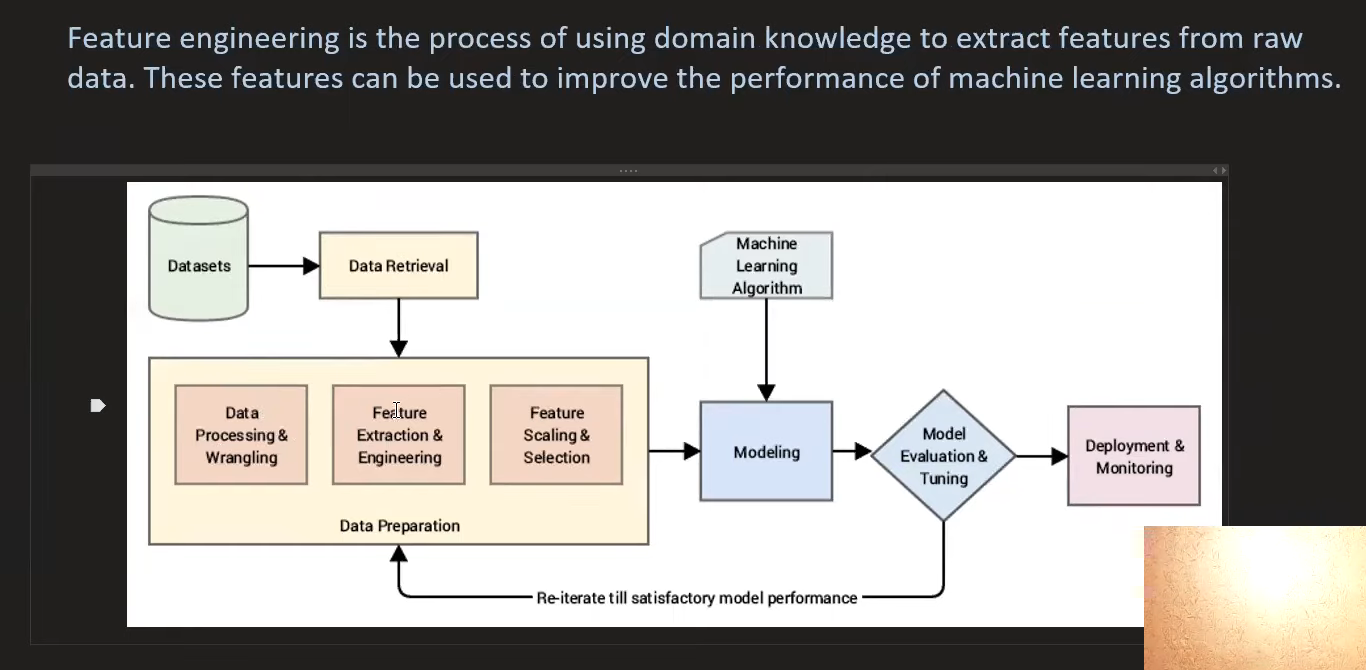

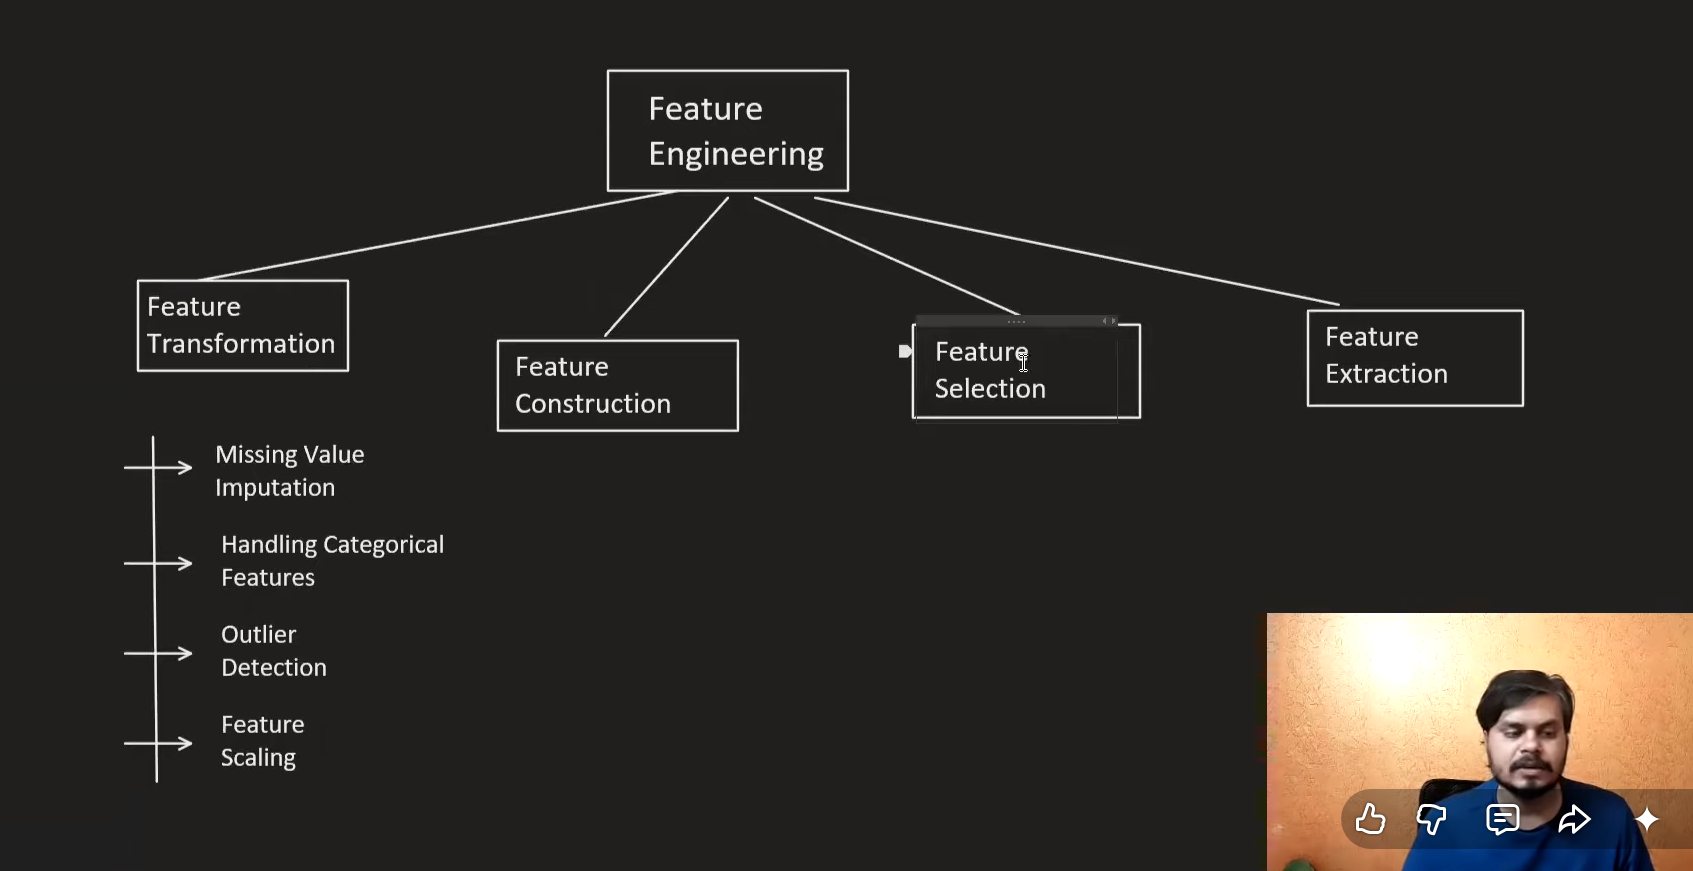

In [8]:
import numpy as np #linear algebra
import pandas as pd #data processing
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df = pd.read_csv('Social_Network_Ads.csv')

In [10]:
df = df.iloc[:,2:]

In [11]:
df.sample(5)

,Purchased
116,0
269,0
42,0
16,1
102,0


## Train Test Split

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.drop('Purchased', axis=1), df['Purchased'],test_size=0.33, random_state=42)
X_train.shape, X_test.shape

((268, 0), (132, 0))

In [13]:
# Reload the data and perform the split properly
df = pd.read_csv('Social_Network_Ads.csv')
df = df.iloc[:, 2:]  # Select Age, EstimatedSalary, and Purchased

X_train, X_test, y_train, y_test = train_test_split(
    df.drop('Purchased', axis=1),
    df['Purchased'],
    test_size=0.33,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
X_train.head()

X_train shape: (268, 0)
X_test shape: (132, 0)


""
258
177
119
194
229


## StandardScaler

In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Reload and properly extract features (Age, EstimatedSalary) and label (Purchased)
df = pd.read_csv('Social_Network_Ads.csv')
# Assuming standard layout: ['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased']
# iloc[:, 2:4] selects 'Age' and 'EstimatedSalary'
X = df.iloc[:, 2:4]
y = df['Purchased']

# 2. Perform train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42
)

# 3. Fit and transform using StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)

# Use 'transform' instead of private '_transform'
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Print shapes to verify
print("Scaled train shape:", X_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

Scaled train shape: (268, 1)
Scaled test shape: (132, 1)


In [15]:
scaler.mean_

array([0.33955224])

In [16]:
X_train_scaled

array([[ 1.39465227],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [ 1.39465227],
       [ 1.39465227],
       [-0.71702461],
       [ 1.39465227],
       [-0.71702461],
       [-0.71702461],
       [ 1.39465227],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [ 1.39465227],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [ 1.39465227],
       [-0.71702461],
       [ 1.39465227],
       [-0.71702461],
       [ 1.39465227],
       [ 1.39465227],
       [-0.71702461],
       [ 1.39465227],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [-0.71702461],
       [ 1.39465227],
       [-0

In [17]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [18]:
# 1. Correctly extract 'Age' and 'EstimatedSalary' as features
X = df[['Age', 'EstimatedSalary']]
y = df['Purchased']

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42
)

# 3. Fit and scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Reconstruct DataFrames with original feature names
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

# 5. Display the statistics of the scaled training data
np.round(X_train_scaled.describe(), 1)

,Age,EstimatedSalary
count,268.0,268.0
mean,-0.0,0.0
std,1.0,1.0
min,-1.9,-1.6
25%,-0.7,-0.8
50%,-0.1,0.0
75%,0.7,0.5
max,2.2,2.3


In [19]:
np.round(X_test_scaled.describe(), 1)

,Age,EstimatedSalary
count,132.0,132.0
mean,0.0,-0.1
std,1.1,1.0
min,-1.9,-1.6
25%,-0.8,-0.9
50%,-0.0,-0.2
75%,0.9,0.5
max,2.2,2.3


### Effect Of Scaling

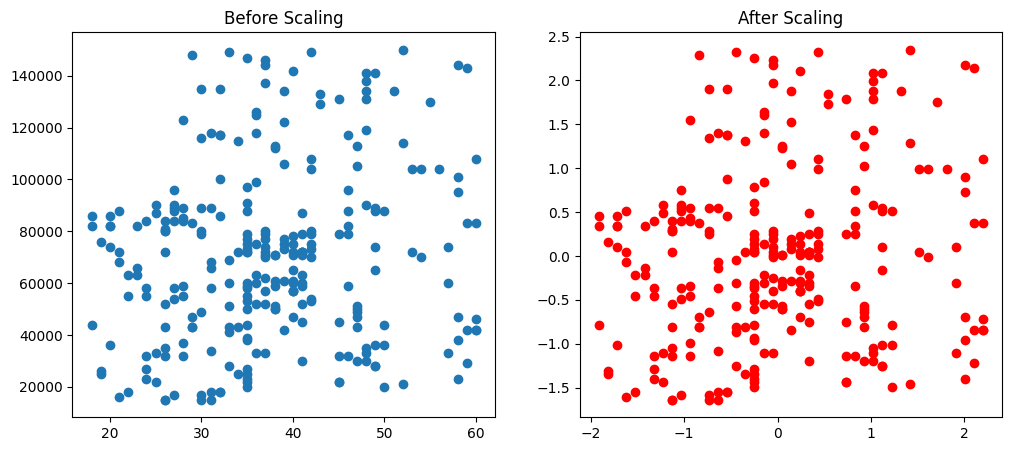

In [20]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))

ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax1.set_title('Before Scaling')
ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'], color='red')
ax2.set_title('After Scaling')
plt.show()

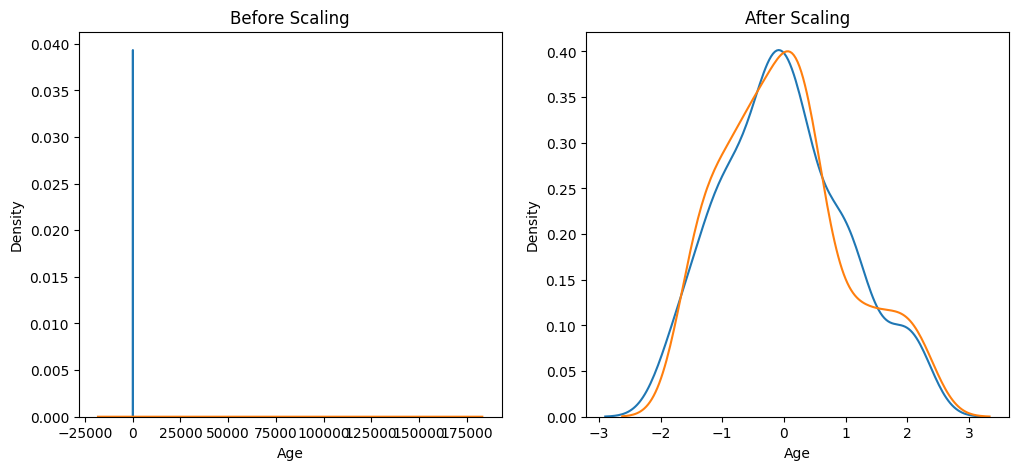

In [22]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))

#before scaling
ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Age'], ax=ax1)
sns.kdeplot(X_train['EstimatedSalary'], ax=ax1)

#after scaling
ax2.set_title('After Scaling')
sns.kdeplot(X_train_scaled['Age'], ax=ax2)
sns.kdeplot(X_train_scaled['EstimatedSalary'], ax=ax2)

plt.show()

### Comparisons of Distributions

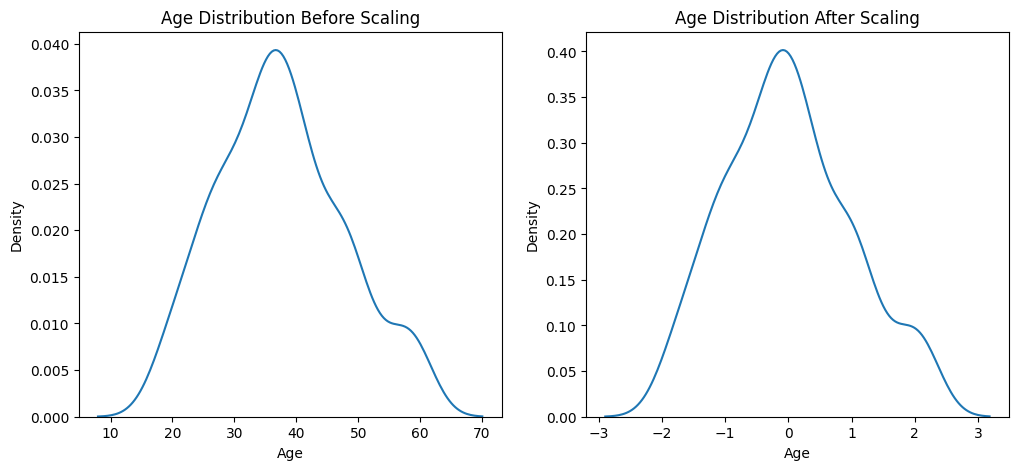

In [24]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))

#before scaling
ax1.set_title('Age Distribution Before Scaling')
sns.kdeplot(X_train['Age'], ax=ax1)

#after scaling
ax2.set_title('Age Distribution After Scaling')
sns.kdeplot(X_train_scaled['Age'], ax=ax2)

plt.show()

### Why Scaling is important ?

In [25]:
from sklearn.linear_model import LogisticRegression

In [26]:
lr = LogisticRegression()
lr_scaled = LogisticRegression()

In [27]:
lr.fit(X_train, y_train)
lr_scaled.fit(X_train_scaled, y_train)

LogisticRegression()

In [28]:
y_pred = lr.predict(X_test)
y_pred_scaled = lr_scaled.predict(X_test_scaled)

In [29]:
from sklearn.metrics import accuracy_score

In [30]:
print("Actual", accuracy_score(y_test, y_pred))
print("Scaled", accuracy_score(y_test, y_pred_scaled))

Actual 0.8333333333333334
Scaled 0.8409090909090909


In [32]:
from sklearn.tree import DecisionTreeClassifier

In [35]:
# 1. Instantiate both Decision Tree models
dt = DecisionTreeClassifier(random_state=42)
dt_scaled = DecisionTreeClassifier(random_state=42)

# 2. Fit the models
dt.fit(X_train, y_train)
dt_scaled.fit(X_train_scaled, y_train)

# 3. Predict and evaluate accuracy to see if scaling affects Decision Trees
y_pred_dt = dt.predict(X_test)
y_pred_dt_scaled = dt_scaled.predict(X_test_scaled)

print("Actual Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Scaled Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt_scaled))

Actual Decision Tree Accuracy: 0.8560606060606061
Scaled Decision Tree Accuracy: 0.8560606060606061


In [36]:
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


### Effect of Outliers

In [38]:
# Define the new outlier data to add
new_data = pd.DataFrame({
    'Age': [5, 90, 95],
    'EstimatedSalary': [1000, 250000, 350000],
    'Purchased': [0, 1, 1]
})

# Use pd.concat instead of .append
df = pd.concat([df, new_data], ignore_index=True)

# Display the last few rows to verify
df.tail()

,Age,EstimatedSalary,Purchased
398,36,33000,0
399,49,36000,1
400,5,1000,0
401,90,250000,1
402,95,350000,1


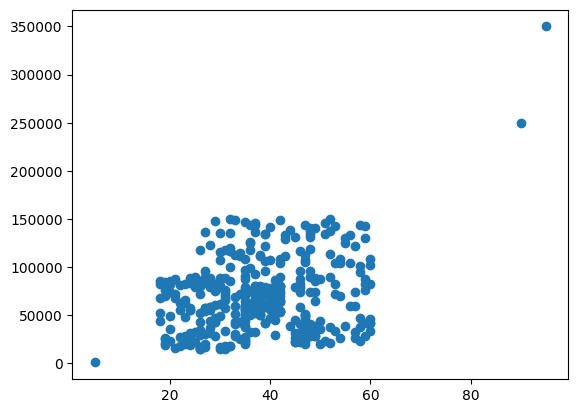

In [39]:
plt.scatter(df['Age'], df['EstimatedSalary'])

In [43]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.drop('Purchased', axis=1), df['Purchased'], test_size=0.33, random_state=0)

X_train.shape, X_test.shape

((270, 2), (133, 2))

In [44]:
from sklearn. preprocessing import StandardScaler

scaler = StandardScaler()

# fit the scaler to the train set, it will learn the parameters
scaler.fit(X_train)

# transform train and test sets
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [45]:
X_train_scaled = pd. DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

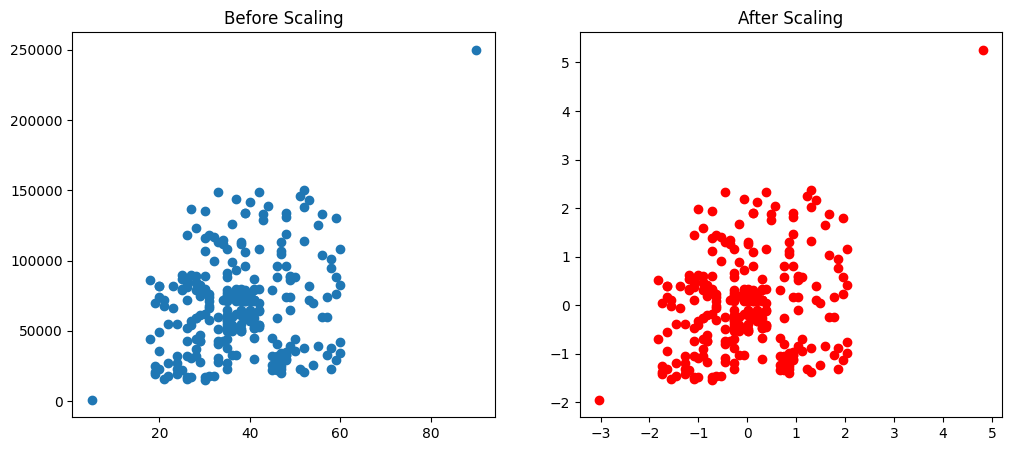

In [46]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(X_train['Age'], X_train['EstimatedSalary' ])
ax1.set_title("Before Scaling")
ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'], color='red')
ax2.set_title("After Scaling")
plt.show()

![image.png](
  

)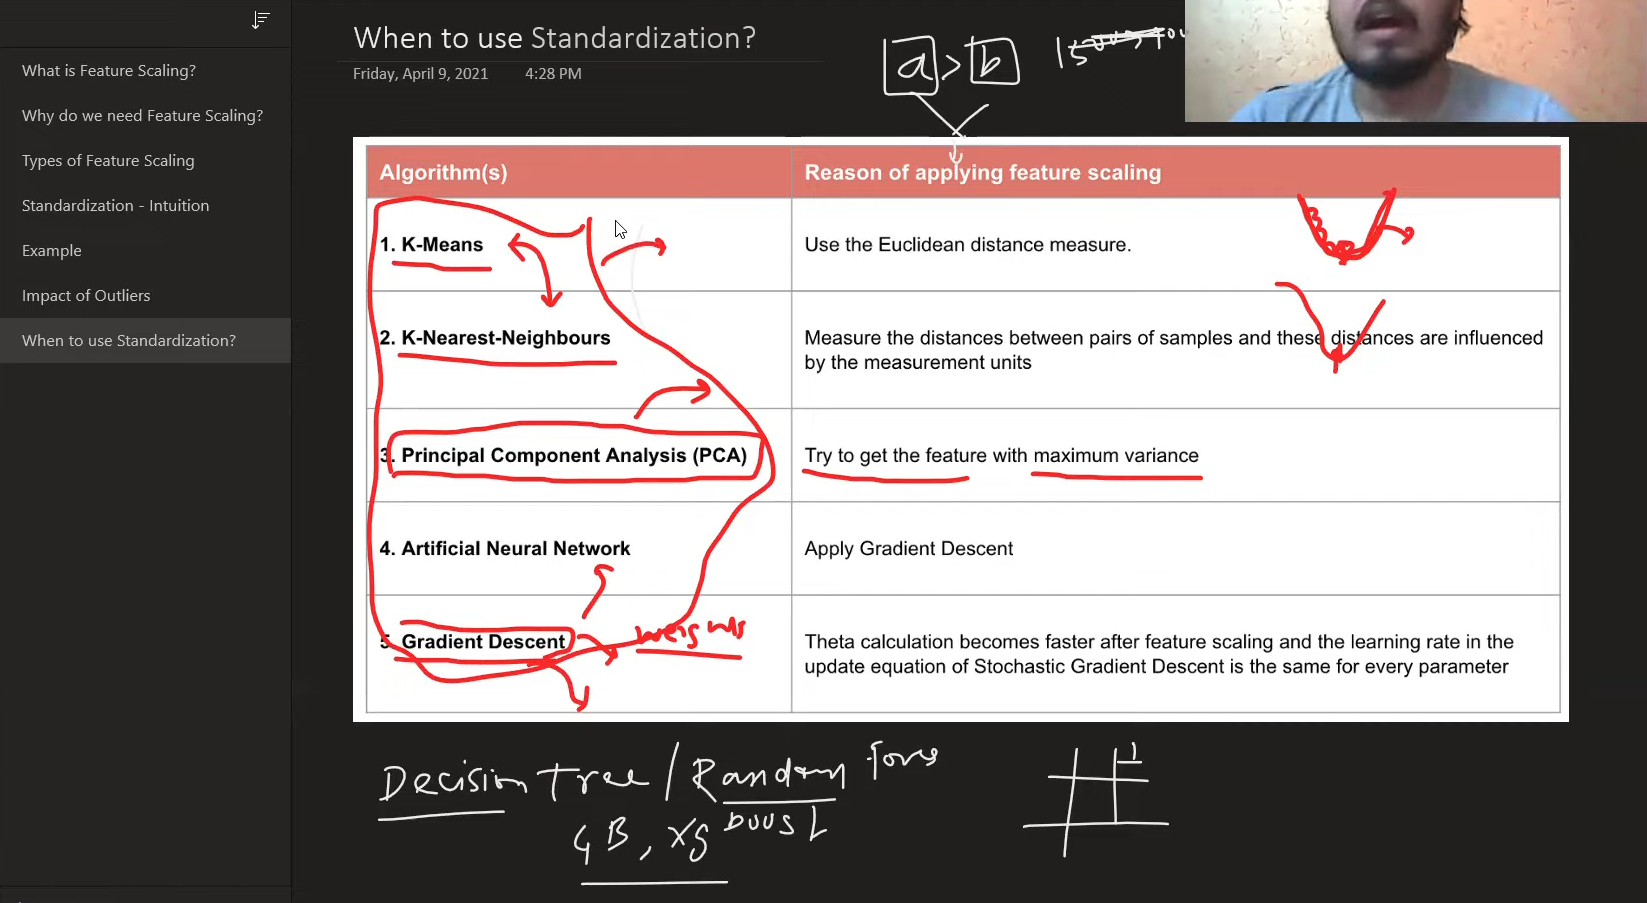